# Zomato data analysis project

In [3]:
# Importing all libraries 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Reading the data set
df = pd.read_csv("Zomato data .csv")

In [5]:
# Reading the first 5 data of data set
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [6]:
# Removing the "/5" from the rate column 
def make_integer(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)
df['rate'] = df['rate'].apply(make_integer)

In [7]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [8]:
df.tail()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
143,Melting Melodies,No,No,3.3,0,100,Dining
144,New Indraprasta,No,No,3.3,0,150,Dining
145,Anna Kuteera,Yes,No,4.0,771,450,Dining
146,Darbar,No,No,3.0,98,800,Dining
147,Vijayalakshmi,Yes,No,3.9,47,200,Dining


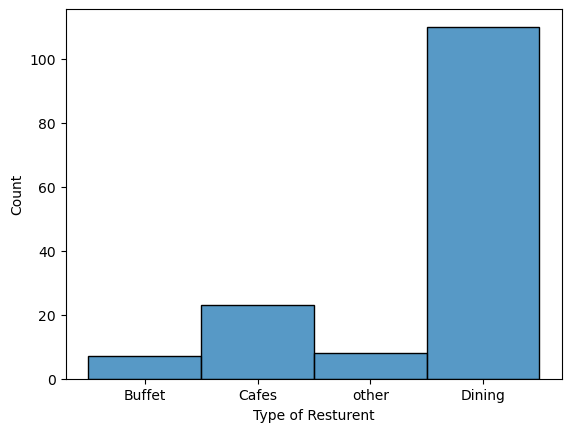

In [9]:
# Types of Resturent 
hist_plot_type = sns.histplot(x = 'listed_in(type)', data = df)

# Or also we can create count plot 
plt.xlabel("Type of Resturent")
plt.show()


Text(0.5, 0, 'Type of Resturent')

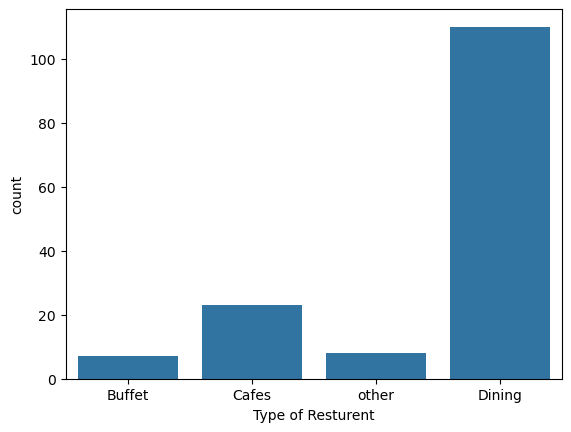

In [10]:

count_plot_type = sns.countplot(x = 'listed_in(type)', data = df)
plt.xlabel("Type of Resturent")

Text(0, 0.5, 'Votes')

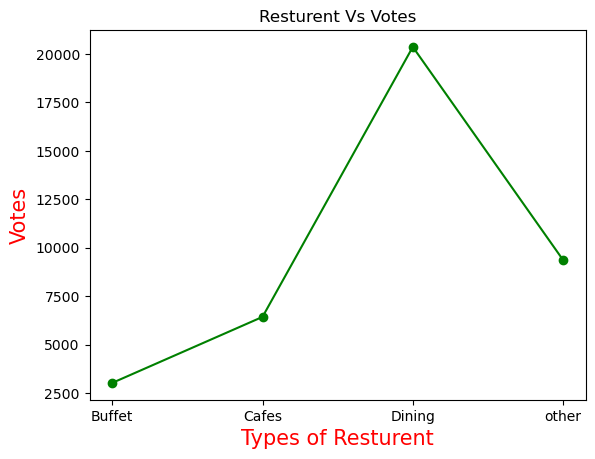

In [35]:
# Types of Resturent vs Votes 
grouped_data = df.groupby('listed_in(type)')['votes'].sum()
result = pd.DataFrame({'votes': grouped_data})
plt.title("Resturent Vs Votes")
plt.plot(result, c = "green", marker = 'o')
plt.xlabel('Types of Resturent', c = 'red', size = 15)
plt.ylabel('Votes', c = 'red', size = 15)

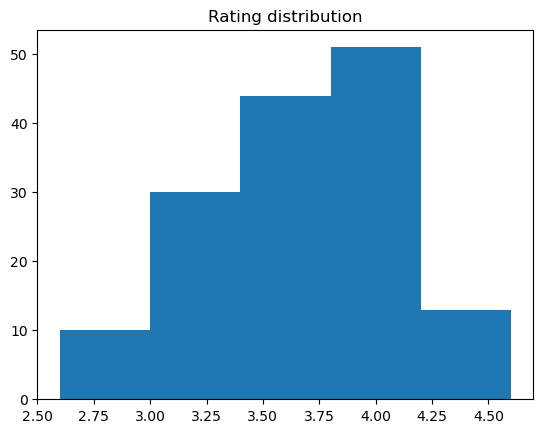

In [12]:
plt.hist(df['rate'], bins = 5)
plt.title("Rating distribution")
plt.show()

In [13]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

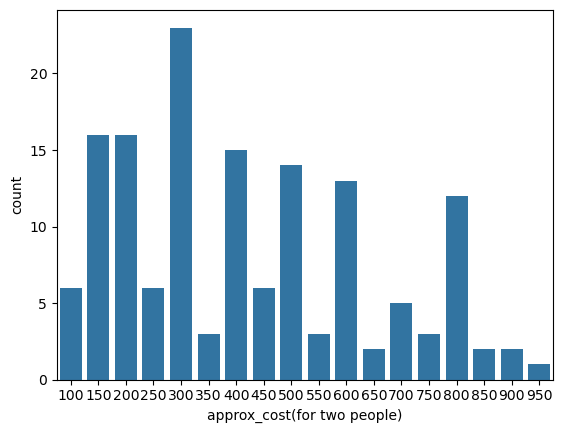

In [14]:
# Maximum spending of food 

max_spending = df['approx_cost(for two people)']
sns.countplot(x = max_spending)


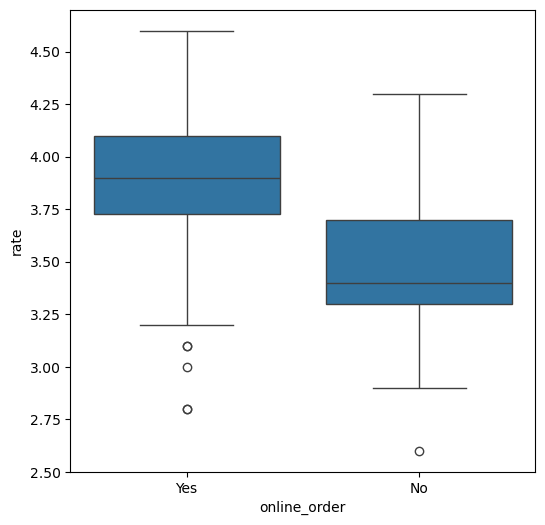

In [15]:
# Which mode recieve maximum rating 
plt.figure(figsize = (6,6))
sns.boxplot(x = 'online_order', y = 'rate', data = df)
plt.show()

# Conclusion --  offline order recieved lower rating then Online order


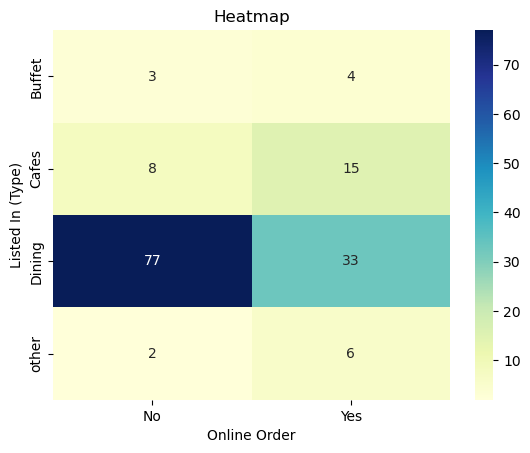

In [16]:
pivot_table = df.pivot_table(index = 'listed_in(type)', columns = 'online_order', aggfunc = 'size')
sns.heatmap(pivot_table, annot = True, cmap="YlGnBu", fmt = "d")
plt.title("Heatmap")
plt.xlabel("Online Order")
plt.ylabel("Listed In (Type)")
plt.show()

In [17]:
pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6
